In [ ]:

import matplotlib.pyplot as plt
from PIL import Image #Python Imaging Library , used to open and handle image files.
import random
import os
import tensorflow as tf
from tensorflow import keras
import numpy as np
from sklearn.model_selection import train_test_split

In [ ]:
!pip install -q kaggle #dowloading kaggle

Uploading data

In [ ]:
from google.colab import files
uploaded = files.upload()  # uploading kaggle.json file including the api key

Saving kaggle.json to kaggle.json


In [ ]:
!mkdir -p ~/.kaggle
!mv kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json


In [ ]:
!kaggle datasets download -d paultimothymooney/breast-histopathology-images

Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/breast-histopathology-images
License(s): CC0-1.0
 98% 3.04G/3.10G [00:32<00:00, 94.6MB/s]
100% 3.10G/3.10G [00:32<00:00, 103MB/s] 


In [ ]:
!unzip -o -q breast-histopathology-images.zip



In [ ]:
np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)
# عشان يكون نفس التقسيم لكل مرة
# Ensures reproducibility



Exploring the data

In [ ]:
import os

os.listdir() #the dataset list


['.config',
 '12948',
 '12877',
 '13591',
 '13458',
 '10274',
 '9178',
 '9261',
 '14081',
 '10282',
 '12895',
 '14082',
 '14156',
 '15512',
 '15902',
 '10304',
 '10305',
 '16085',
 '10257',
 '12896',
 '10256',
 '13687',
 '16166',
 '13666',
 '9267',
 '12823',
 '15472',
 '12241',
 '16014',
 '13688',
 '8956',
 '13916',
 '10285',
 '16533',
 '14210',
 '9257',
 '13018',
 '9124',
 '14153',
 '12752',
 '16570',
 '9123',
 '14213',
 '8918',
 '12879',
 '10308',
 '9228',
 '16552',
 'IDC_regular_ps50_idx5',
 '9035',
 '14154',
 '9075',
 '9226',
 '9254',
 '15634',
 '16896',
 '13019',
 '15471',
 '10273',
 '13692',
 '16554',
 '10275',
 '10261',
 '9321',
 '12909',
 '12880',
 '8984',
 '14078',
 '16569',
 '10278',
 '12810',
 '15840',
 '12890',
 '8975',
 '12750',
 '15473',
 '10277',
 '15515',
 '9083',
 '12824',
 '12911',
 '12883',
 '13023',
 '10269',
 '12820',
 '12900',
 '9382',
 '16895',
 '12947',
 '12819',
 '9043',
 '12749',
 '10253',
 '14212',
 '14305',
 '9174',
 '8950',
 '9319',
 '10290',
 '13400',
 '12

In [ ]:
os.listdir("IDC_regular_ps50_idx5")[:5]
#first five files (patients id)

['12948', '12877', '13591', '13458', '10274']

In [ ]:
dataset="IDC_regular_ps50_idx5"   #the dataset name


In [ ]:
import os

dataset_folder = "IDC_regular_ps50_idx5"

# كل مجلد داخل dataset يمثل مريض
patients = [name for name in os.listdir(dataset_folder) if os.path.isdir(os.path.join(dataset_folder, name))]

num_patients = len(patients)
print("Number of patients in the dataset:", num_patients)


Number of patients in the dataset: 279


In [ ]:
import os

dataset_folder = "IDC_regular_ps50_idx5"

# Dictionary to store counts
patient_image_counts = {}

for patient in os.listdir(dataset_folder):
    patient_path = os.path.join(dataset_folder, patient)
    if not os.path.isdir(patient_path):
        continue

    class_counts = {}
    for class_label in ["0", "1"]:  # 0 = benign, 1 = malignant
        class_path = os.path.join(patient_path, class_label)
        if os.path.exists(class_path):
            # Count images in this class folder
            num_images = len([f for f in os.listdir(class_path) if f.endswith((".png", ".jpg", ".jpeg"))])
            class_counts[class_label] = num_images
        else:
            class_counts[class_label] = 0

    patient_image_counts[patient] = class_counts

# Print results
for patient, counts in patient_image_counts.items():
    print(f"Patient {patient}: Benign (0) = {counts['0']}, Malignant (1) = {counts['1']}")


Patient 12948: Benign (0) = 80, Malignant (1) = 87
Patient 12877: Benign (0) = 272, Malignant (1) = 33
Patient 13591: Benign (0) = 907, Malignant (1) = 128
Patient 13458: Benign (0) = 394, Malignant (1) = 49
Patient 10274: Benign (0) = 659, Malignant (1) = 219
Patient 9178: Benign (0) = 1283, Malignant (1) = 160
Patient 9261: Benign (0) = 521, Malignant (1) = 446
Patient 14081: Benign (0) = 117, Malignant (1) = 209
Patient 10282: Benign (0) = 1835, Malignant (1) = 198
Patient 12895: Benign (0) = 939, Malignant (1) = 741
Patient 14082: Benign (0) = 281, Malignant (1) = 197
Patient 14156: Benign (0) = 1201, Malignant (1) = 197
Patient 15512: Benign (0) = 79, Malignant (1) = 143
Patient 15902: Benign (0) = 706, Malignant (1) = 461
Patient 10304: Benign (0) = 779, Malignant (1) = 101
Patient 10305: Benign (0) = 1802, Malignant (1) = 19
Patient 16085: Benign (0) = 1913, Malignant (1) = 24
Patient 10257: Benign (0) = 427, Malignant (1) = 208
Patient 12896: Benign (0) = 424, Malignant (1) = 8

Collecting images paths and labeling

In [ ]:
dataset = "IDC_regular_ps50_idx5"

image_paths = []
labels = []
class_malignant = []
class_benign = []

# Loop through each patient folders to get their paths
for patient_folder in os.listdir(dataset):
    patient_path = os.path.join(dataset, patient_folder)

    # Loop through class folders (0 and 1)
    for img_class in os.listdir(patient_path):
        class_path = os.path.join(patient_path, img_class)
        if os.path.isdir(class_path):
            # Loop through images inside the class folder
            for img_name in os.listdir(class_path):
                if img_name.lower().endswith(".png"):
                    full_path = os.path.join(class_path, img_name)
                    image_paths.append(full_path)
                    labels.append(int(img_class))
                    # seperate the classes
                    # class (0,1)
                    if img_class == '1':
                        class_malignant.append(full_path)
                    else:
                        class_benign.append(full_path)


In [ ]:
print("Total images in the dataset (size):", len(image_paths))
print("Total Malignant(Cancer) images (class 1):", len(class_malignant))
print("Total Benign (non-cancer) images (class 0):", len(class_benign))

Total images in the dataset (size): 277524
Total Malignant(Cancer) images (class 1): 78786
Total Benign (non-cancer) images (class 0): 198738


In [ ]:
for path in class_malignant[:3]:
    img = Image.open(path)
    print(path, img.size)  # the size and path for the first three images  in the malignant class


IDC_regular_ps50_idx5/12870/1/12870_idx5_x751_y1851_class1.png (50, 50)
IDC_regular_ps50_idx5/12870/1/12870_idx5_x701_y1851_class1.png (50, 50)
IDC_regular_ps50_idx5/12870/1/12870_idx5_x751_y2051_class1.png (50, 50)


In [ ]:
for path in class_benign[:3]:
    img = Image.open(path)
    print(path, img.size) # the size and path for the first three images  in the benign class

IDC_regular_ps50_idx5/12870/0/12870_idx5_x2451_y1851_class0.png (50, 50)
IDC_regular_ps50_idx5/12870/0/12870_idx5_x1851_y2051_class0.png (50, 50)
IDC_regular_ps50_idx5/12870/0/12870_idx5_x2901_y2501_class0.png (50, 50)


Visualization

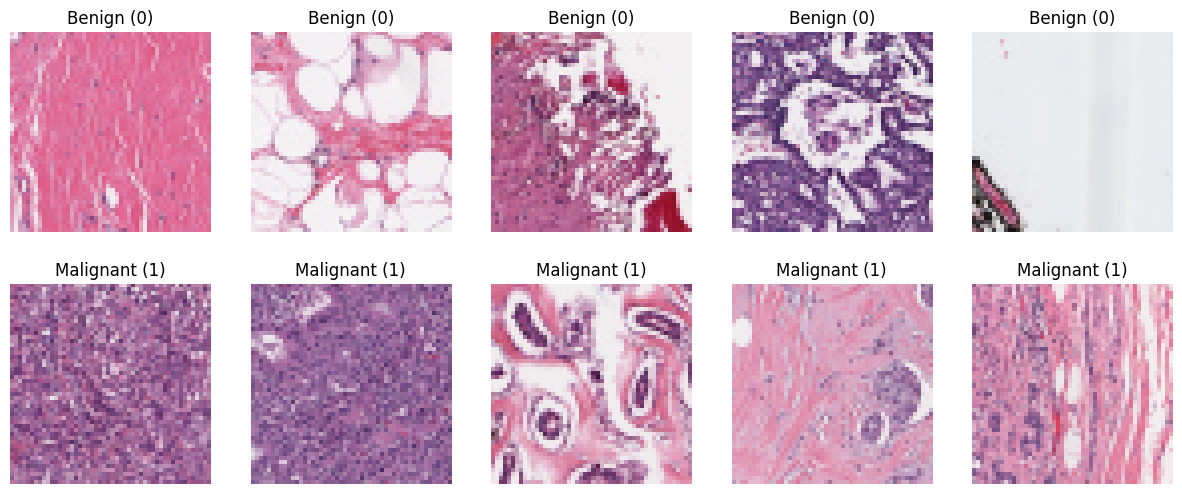

In [ ]:

#taking images randomly from each class for visualizing

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for i, path in enumerate(random.sample(class_benign, 5)):
    img = Image.open(path)
    axes[0, i].imshow(img)
    axes[0, i].set_title("Benign (0)")
    axes[0, i].axis("off")

for i, path in enumerate(random.sample(class_malignant, 5)):
    img = Image.open(path)
    axes[1, i].imshow(img)
    axes[1, i].set_title("Malignant (1)")
    axes[1, i].axis("off")

plt.show()


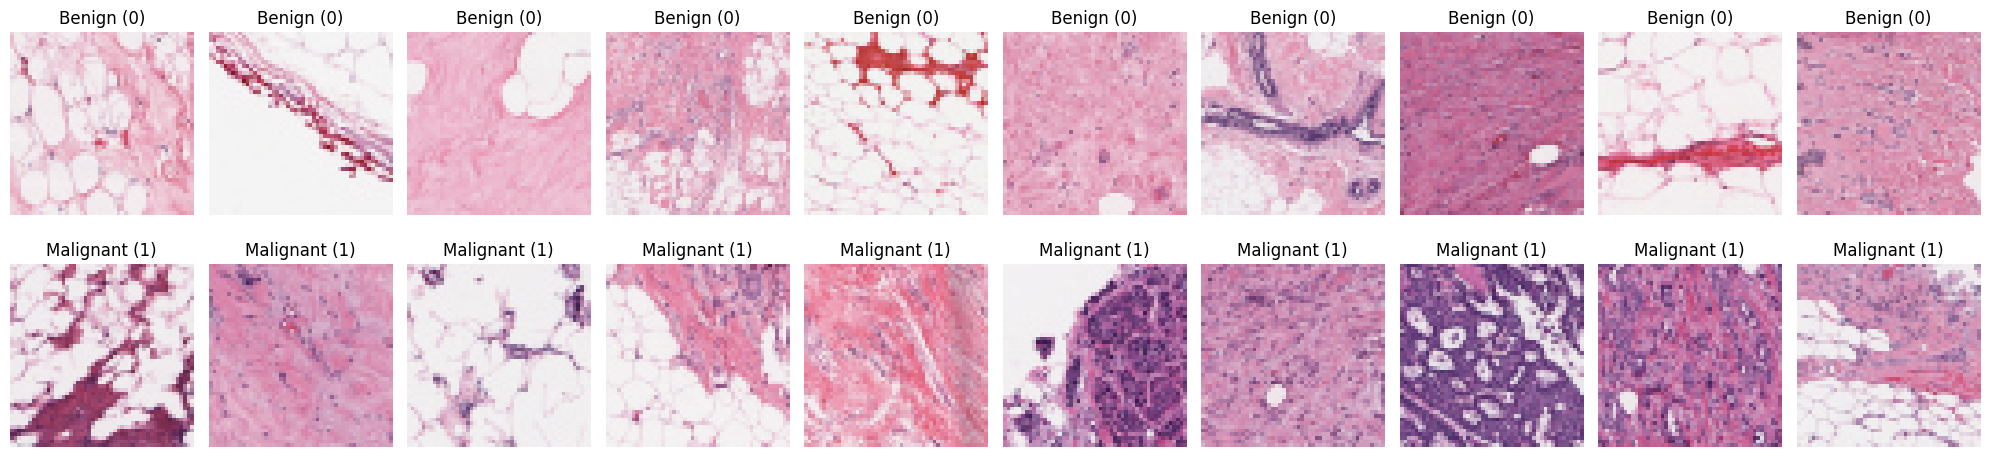

In [ ]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

# The lists 'class_benign' and 'class_malignant' already contain full paths
# to images of each class, which were correctly populated earlier.

num_samples = 10  # Number of images to display for each class
fig, axes = plt.subplots(2, num_samples, figsize=(20, 5))

# Display benign images (class 0)
for j, path in enumerate(random.sample(class_benign, num_samples)):
    img = Image.open(path)
    axes[0, j].imshow(img)
    axes[0, j].set_title("Benign (0)")
    axes[0, j].axis('off')
    if j == 0:
        axes[0, j].set_ylabel("Benign (0)", size=14)

# Display malignant images (class 1)
for j, path in enumerate(random.sample(class_malignant, num_samples)):
    img = Image.open(path)
    axes[1, j].imshow(img)
    axes[1, j].set_title("Malignant (1)")
    axes[1, j].axis('off')
    if j == 0:
        axes[1, j].set_ylabel("Malignant (1)", size=14)

plt.tight_layout()
plt.show()

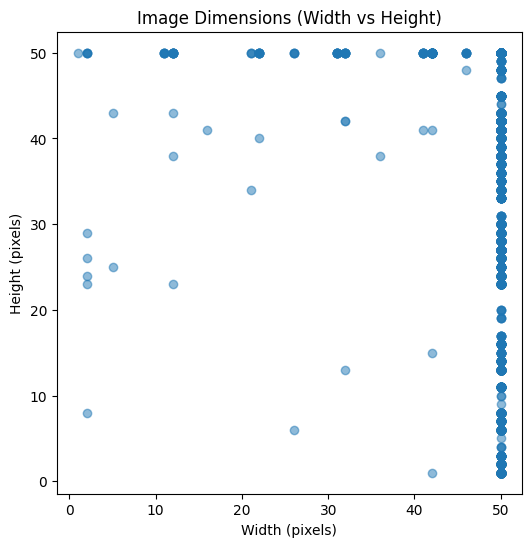

In [ ]:
import os
from PIL import Image
import matplotlib.pyplot as plt

widths = []
heights = []

# loop over images
for root, dirs, files in os.walk(dataset):
    for file in files:
        if file.endswith((".png", ".jpg", ".jpeg")):
            img_path = os.path.join(root, file)
            img = Image.open(img_path)
            w, h = img.size
            widths.append(w)
            heights.append(h)

# scatter plot
plt.figure(figsize=(6, 6))
plt.scatter(widths, heights, alpha=0.5)
plt.xlabel("Width (pixels)")
plt.ylabel("Height (pixels)")
plt.title("Image Dimensions (Width vs Height)")
plt.show()


Image shape: (50, 50, 3)


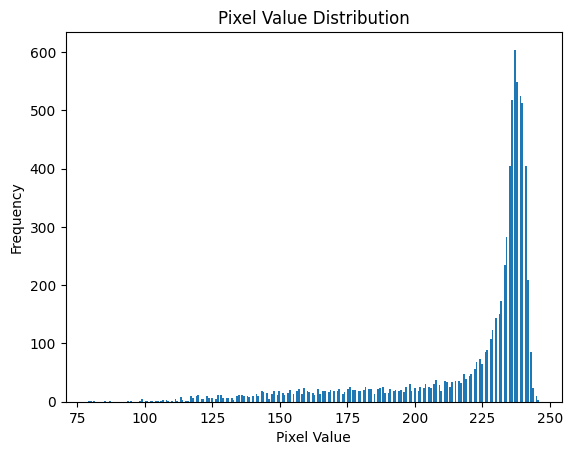

In [ ]:


#Image size
#Number of channels

img = np.array(Image.open(image_paths[0])) # converts the image into a NumPy array
print("Image shape:", img.shape) # 3 color channels (RGB) , pixels = 50 X 50

plt.hist(img.ravel(), bins=256)
plt.title("Pixel Value Distribution")
plt.xlabel("Pixel Value")
plt.ylabel("Frequency")
plt.show()  #Ensures pixel values are within expected range


In [ ]:
import cv2
import os

gray_count = 0
color_count = 0

for path in image_paths:
    img = cv2.imread(path)  # يقرأ الصورة
    if img is None:
        continue  # تجاهل الصور التالفة
    if len(img.shape) == 2:  # فقط صفوف و أعمدة → Grayscale
        gray_count += 1
    elif len(img.shape) == 3:  # صفوف × أعمدة × قنوات → RGB/BGR
        color_count += 1

print("Number of Grayscale images:", gray_count)
print("Number of Color images (RGB/BGR):", color_count)

Number of Grayscale images: 0
Number of Color images (RGB/BGR): 277524


In [ ]:
import numpy as np
import cv2

mean_values = []  # List to store mean pixel values of all images

for img_path in image_paths:
    img = cv2.imread(img_path)
    if img is None:
        continue  # Skip corrupted images


    # Compute mean pixel value and store it
    mean_val = img.mean()
    mean_values.append(mean_val)

# Compute the average pixel value across all images
dataset_avg = np.mean(mean_values)
print("Average pixel value across all images:", dataset_avg)


Average pixel value across all images: 185.3802211061105


/tmp/ipython-input-3974463159.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Non-Cancer", "Cancer"], y=class_counts, palette="Set2")


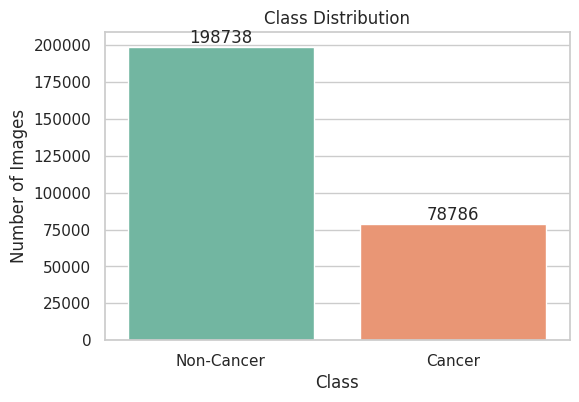

In [ ]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

classes = ["0", "1"]

# حساب عدد الصور في كل فئة
class_counts = []
for cls in classes:
    # Iterate through all patient folders to count images for each class
    count = 0
    for patient_folder in os.listdir(dataset):
        class_path = os.path.join(dataset, patient_folder, cls)
        if os.path.isdir(class_path):
            count += len(os.listdir(class_path))
    class_counts.append(count)

# رسم Bar Chart
sns.set(style="whitegrid")
plt.figure(figsize=(6,4))
sns.barplot(x=["Non-Cancer", "Cancer"], y=class_counts, palette="Set2")
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")

# وضع قيمة العدد فوق كل bar
for i, count in enumerate(class_counts):
    plt.text(i, count + 10, str(count), ha='center', va='bottom', fontsize=12)

plt.show()

Splitting the data (train,val,test)

In [ ]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras import layers, models, callbacks
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix

# ===============================
# 1️⃣ Load Dataset
# ===============================

DATASET_PATH = "IDC_regular_ps50_idx5"

image_paths, labels, patient_ids = [], [], []

for patient in os.listdir(DATASET_PATH):
    patient_path = os.path.join(DATASET_PATH, patient)
    if not os.path.isdir(patient_path):
        continue
    for cls in ['0', '1']:
        class_path = os.path.join(patient_path, cls)
        if os.path.isdir(class_path):
            for img in os.listdir(class_path):
                if img.endswith(".png"):
                    image_paths.append(os.path.join(class_path, img))
                    labels.append(int(cls))
                    patient_ids.append(patient)

df = pd.DataFrame({
    "image_path": image_paths,
    "label": labels,
    "patient_id": patient_ids
})

print("Total images:", len(df))
print("Class distribution:\n", df['label'].value_counts())

# ===============================
# 2️⃣ Patient-wise Split (NO Leakage)
# ===============================

patients_df = df[['patient_id', 'label']].drop_duplicates('patient_id')

train_pat, temp_pat = train_test_split(
    patients_df,
    test_size=0.2,
    stratify=patients_df['label'],
    random_state=42
)

val_pat, test_pat = train_test_split(
    temp_pat,
    test_size=0.5,
    stratify=temp_pat['label'],
    random_state=42
)

train_df = df[df['patient_id'].isin(train_pat['patient_id'])]
val_df   = df[df['patient_id'].isin(val_pat['patient_id'])]
test_df  = df[df['patient_id'].isin(test_pat['patient_id'])]

print("\nAfter patient split:")
print("Train:\n", train_df['label'].value_counts())
print("Val:\n", val_df['label'].value_counts())
print("Test:\n", test_df['label'].value_counts())

# ===============================
# 3️⃣ tf.data Pipeline
# ===============================

IMG_SIZE = (50, 50)
BATCH_SIZE = 32

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_png(img, channels=3) #convert the file into image
    img = tf.image.resize(img, IMG_SIZE)      #make them with one size
    img = tf.cast(img, tf.float32) / 255.0   # convert the pixel from (0-255) into (0-1)
    return img, label

def make_dataset(df, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((df['image_path'], df['label']))  #there is no open for images, just the name of image and its type.   from_tensor_slices--> get the the images name
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)  #open images
    if shuffle:
        ds = ds.shuffle(1000)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_df, shuffle=True)
val_ds   = make_dataset(val_df)
test_ds  = make_dataset(test_df)

# ===============================
# 4️⃣ Handle Class Imbalance
# ===============================

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.array([0,1]),
    y=train_df['label']
)
class_weights = dict(enumerate(class_weights))

print("\nClass Weights:", class_weights)
print("\nSamples used for training:")
print("Class 0:", np.sum(train_df['label'] == 0))
print("Class 1:", np.sum(train_df['label'] == 1))



Total images: 277524
Class distribution:
 label
0    198738
1     78786
Name: count, dtype: int64

After patient split:
Train:
 label
0    159316
1     58889
Name: count, dtype: int64
Val:
 label
0    20980
1    10081
Name: count, dtype: int64
Test:
 label
0    18442
1     9816
Name: count, dtype: int64

Class Weights: {0: np.float64(0.68481822290291), 1: np.float64(1.852680466640629)}

Samples used for training:
Class 0: 159316
Class 1: 58889


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Baseline model
baseline_model = models.Sequential([
    layers.Input(shape=(50, 50, 3)),

    # طبقة Conv واحدة بسيطة
    layers.Conv2D(16, 3, activation='relu', padding='same'),
    layers.MaxPooling2D(),

    # Flatten لتحويل الخرائط إلى vector
    layers.Flatten(),

    # Dense output
    layers.Dense(1, activation='sigmoid')
])

# Compile
baseline_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.Recall(name='recall')]
)

# Summary
baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 50, 50, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 25, 25, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 10000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │        10,001 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,449 (40.82 KB)

 Trainable params: 10,449 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

baseline_model = models.Sequential([
    layers.Input(shape=(50, 50, 3)),
    layers.Conv2D(16, 3, activation='relu', padding='same'),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(1, activation='sigmoid')
])

baseline_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.Recall(name='recall')]
)

history = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    batch_size=32,
    class_weight=class_weights
)

y_pred_prob = baseline_model.predict(test_ds)
y_pred = (y_pred_prob >= 0.5).astype(int)

# Flatten test_labels from test_ds to get a 1D array for confusion_matrix and classification_report
# Collect true labels from test_ds
true_labels = []
for _, labels in test_ds:
    true_labels.extend(labels.numpy())
true_labels = np.array(true_labels)

cm = confusion_matrix(true_labels, y_pred)
print(cm)

report = classification_report(true_labels, y_pred, target_names=['Benign', 'Malignant'])
print(report)

Epoch 1/5
6819/6819 ━━━━━━━━━━━━━━━━━━━━ 92s 13ms/step - accuracy: 0.8208 - loss: 0.4221 - recall: 0.7456 - val_accuracy: 0.7969 - val_loss: 0.5297 - val_recall: 0.8024
Epoch 2/5
6819/6819 ━━━━━━━━━━━━━━━━━━━━ 72s 10ms/step - accuracy: 0.8255 - loss: 0.4113 - recall: 0.7682 - val_accuracy: 0.7874 - val_loss: 0.5289 - val_recall: 0.5046
Epoch 3/5
6819/6819 ━━━━━━━━━━━━━━━━━━━━ 72s 11ms/step - accuracy: 0.8295 - loss: 0.4051 - recall: 0.7720 - val_accuracy: 0.7172 - val_loss: 0.6139 - val_recall: 0.9064
Epoch 4/5
6819/6819 ━━━━━━━━━━━━━━━━━━━━ 65s 9ms/step - accuracy: 0.8423 - loss: 0.3956 - recall: 0.7694 - val_accuracy: 0.7436 - val_loss: 0.6114 - val_recall: 0.9006
Epoch 5/5
6819/6819 ━━━━━━━━━━━━━━━━━━━━ 64s 9ms/step - accuracy: 0.8420 - loss: 0.3956 - recall: 0.7694 - val_accuracy: 0.7856 - val_loss: 0.5208 - val_recall: 0.8544
884/884 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step
[[14523  3919]
 [ 1715  8101]]
              precision    recall  f1-score   support

      Benign       0.89      